Matplotlib is building the font cache; this may take a moment.


=== BẢNG SO SÁNH TRƯỚC VÀ SAU KHI XỬ LÝ OUTLIER (ISSUE #2) ===
                          Sales (Gốc)  Log_Sales (Log1p)  Sales_Capped (IQR)  \
Số dòng (Count)               9789.00            9789.00             9789.00   
Trung bình (Mean)              230.12               4.16              140.61   
Độ lệch chuẩn (Std)            625.30               1.59              169.30   
Nhỏ nhất (Min)                   0.44               0.37                0.44   
Q1 (25%)                        17.25               2.90               17.25   
Trung vị (Median 50%)           54.38               4.01               54.38   
Q3 (75%)                       210.39               5.35              210.39   
Lớn nhất (Max)               22638.48              10.03              500.11   
Độ lệch (Skewness)              13.05               0.28                1.22   
Độ nhọn (Kurtosis)             307.31              -0.59               -0.01   
% Tổng Doanh Thu giữ lại       100.00             100.00 

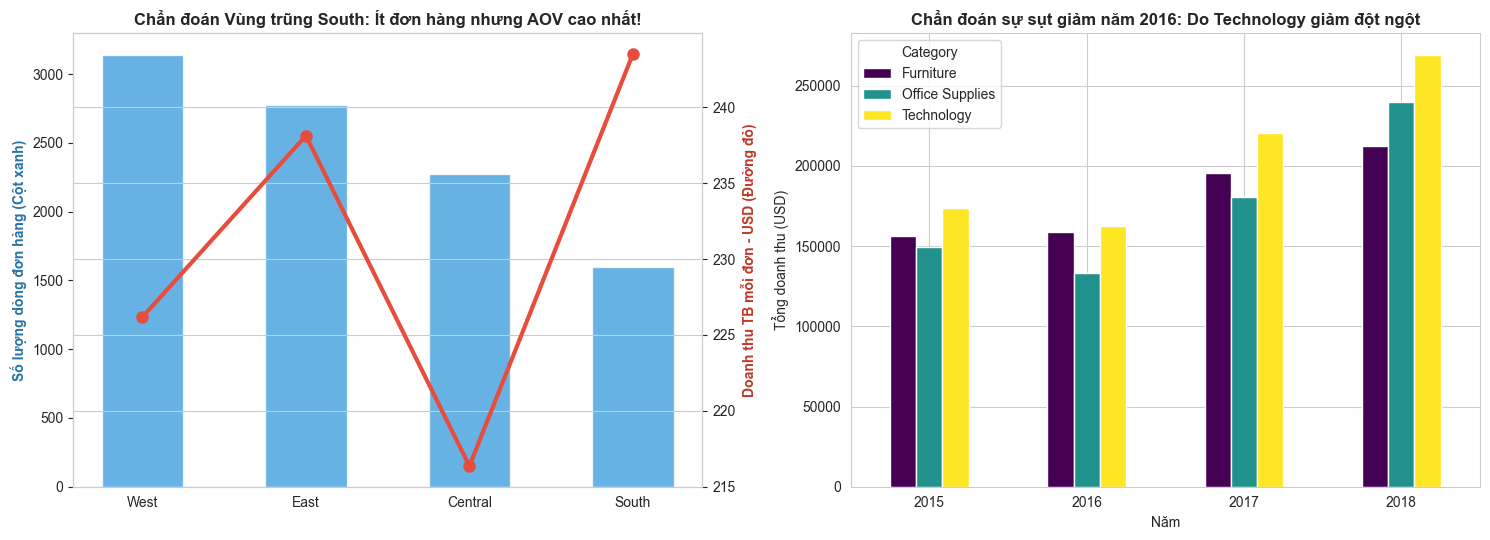

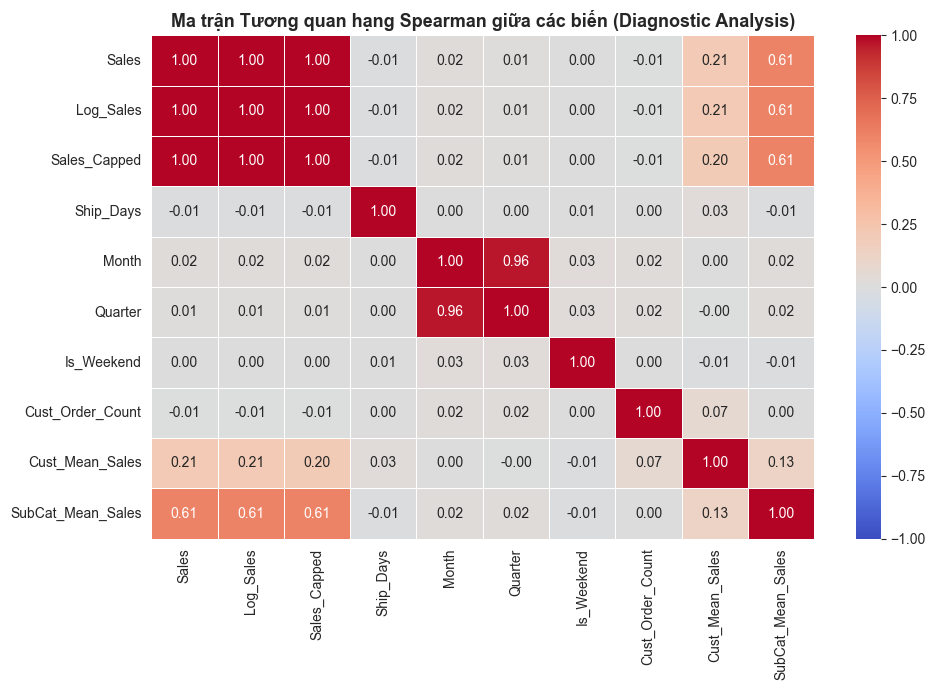

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# 1. Khắc phục thiếu sót cấu trúc thư mục: Tạo data/processed và reports/figures
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)

duong_dan = "../data/raw/train.csv" if os.path.exists("../data/raw/train.csv") else "train.csv"
df = pd.read_csv(duong_dan)

# Làm sạch 11 dòng thiếu Postal Code -> còn 9,789 dòng
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True, errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True, errors="coerce")
df = df.dropna(subset=["Postal Code"]).copy()

# 2. Giải quyết Issue #3 (Transform & Merge dữ liệu từ nhiều nguồn/bảng tổng hợp)
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Quarter"] = df["Order Date"].dt.quarter
df["DayOfWeek"] = df["Order Date"].dt.day_name()
df["Is_Weekend"] = df["Order Date"].dt.dayofweek.isin([5, 6]).astype(int)
df["Ship_Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

# Tạo bảng RFM/Hành vi khách hàng và bảng Quy mô Ngành hàng rồi MERGE vào bảng chính
customer_stats = df.groupby("Customer ID").agg(
    Cust_Order_Count=("Order ID", "nunique"),
    Cust_Item_Count=("Sales", "count"),
    Cust_Mean_Sales=("Sales", "mean")
).reset_index()

subcat_stats = df.groupby("Sub-Category").agg(
    SubCat_Mean_Sales=("Sales", "mean")
).reset_index()

df = df.merge(customer_stats, on="Customer ID", how="left")
df = df.merge(subcat_stats, on="Sub-Category", how="left")

# 3. Giải quyết Issue #2: Lập bảng so sánh chi tiết Trước và Sau khi xử lý Outlier
Q1, Q3 = df["Sales"].quantile(0.25), df["Sales"].quantile(0.75)
IQR = Q3 - Q1
low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

df["Is_Outlier"] = ((df["Sales"] < low) | (df["Sales"] > high)).astype(int)
df["Log_Sales"] = np.log1p(df["Sales"])
df["Sales_Capped"] = np.clip(df["Sales"], low, high)
sales_removed = df[df["Is_Outlier"] == 0]["Sales"]

def get_metrics(s, total_rev):
    return {
        "Số dòng (Count)": len(s),
        "Trung bình (Mean)": s.mean(),
        "Độ lệch chuẩn (Std)": s.std(),
        "Nhỏ nhất (Min)": s.min(),
        "Q1 (25%)": s.quantile(0.25),
        "Trung vị (Median 50%)": s.median(),
        "Q3 (75%)": s.quantile(0.75),
        "Lớn nhất (Max)": s.max(),
        "Độ lệch (Skewness)": s.skew(),
        "Độ nhọn (Kurtosis)": s.kurt(),
        "% Tổng Doanh Thu giữ lại": (s.sum() / total_rev) * 100
    }

total_rev = df["Sales"].sum()
comp_table = pd.DataFrame({
    "Sales (Gốc)": get_metrics(df["Sales"], total_rev),
    "Log_Sales (Log1p)": get_metrics(df["Log_Sales"], df["Log_Sales"].sum()),
    "Sales_Capped (IQR)": get_metrics(df["Sales_Capped"], total_rev),
    "Sales_Removed (Xóa Outlier)": get_metrics(sales_removed, total_rev)
}).round(2)

print("=== BẢNG SO SÁNH TRƯỚC VÀ SAU KHI XỬ LÝ OUTLIER (ISSUE #2) ===")
print(comp_table)
comp_table.to_csv("../data/processed/outlier_comparison_table.csv")

# Lưu file dữ liệu sạch hoàn chỉnh vào data/processed/
df.to_csv("../data/processed/superstore_cleaned.csv", index=False)

# 4. Giải quyết Issue #5: Phân tích Diagnostic sâu (Vẽ Biểu đồ số 10 và Biểu đồ số 12)
sns.set_style("whitegrid")

# Biểu đồ 10: Giải mã nguyên nhân gốc rễ (Diagnostic) tại sao South thấp & tại sao 2016 giảm
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

reg_diag = df.groupby("Region").agg(
    Orders=("Sales", "count"),
    AOV=("Sales", "mean")
).loc[["West", "East", "Central", "South"]]

ax1 = axes[0]
ax1_sub = ax1.twinx()
ax1.bar(reg_diag.index, reg_diag["Orders"], color="#3498DB", alpha=0.75, width=0.5, label="Số lượng dòng đơn hàng")
ax1_sub.plot(reg_diag.index, reg_diag["AOV"], color="#E74C3C", marker="o", linewidth=3, markersize=8, label="Giá trị TB/đơn - AOV ($)")
ax1.set_title("Chẩn đoán Vùng trũng South: Ít đơn hàng nhưng AOV cao nhất!", fontsize=12, fontweight="bold")
ax1.set_ylabel("Số lượng dòng đơn hàng (Cột xanh)", color="#2874A6", fontweight="bold")
ax1_sub.set_ylabel("Doanh thu TB mỗi đơn - USD (Đường đỏ)", color="#C0392B", fontweight="bold")
ax1.grid(False)

year_cat = df.groupby(["Year", "Category"])["Sales"].sum().unstack()
year_cat.plot(kind="bar", stacked=False, ax=axes[1], colormap="viridis")
axes[1].set_title("Chẩn đoán sự sụt giảm năm 2016: Do Technology giảm đột ngột", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Năm")
axes[1].set_ylabel("Tổng doanh thu (USD)")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig("../reports/figures/10_diagnostic_root_causes.png", dpi=150, bbox_inches="tight")
plt.show()

# Biểu đồ 12: Ma trận tương quan (Correlation Matrix) & Yếu tố ảnh hưởng đến Log_Sales
corr_cols = ["Sales", "Log_Sales", "Sales_Capped", "Ship_Days", "Month", "Quarter", 
             "Is_Weekend", "Cust_Order_Count", "Cust_Mean_Sales", "SubCat_Mean_Sales"]
corr_matrix = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Ma trận Tương quan hạng Spearman giữa các biến (Diagnostic Analysis)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/figures/12_diagnostic_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()